# Zone-wise Power Demand Forecasting & Demand-Pattern Segmentation

## 1. Introduction

This project focuses on analyzing and forecasting electricity consumption across three different zones of Tetouan City.

The main objective is to understand electricity demand patterns, develop machine learning models for hourly-ahead power consumption forecasting, and identify demand patterns using clustering techniques.

## 2. Project Objectives

- Perform Exploratory Data Analysis (EDA).
- Clean and preprocess the dataset.
- Engineer time-based, lag and rolling features.
- Develop Random Forest forecasting models for three zones.
- Evaluate model performance using MAE, RMSE and R².
- Apply K-Means and Hierarchical Clustering.
- Develop a reusable inference script.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Load the dataset
file_path = "../data/Tetuan City power consumption.csv"

df = pd.read_csv(file_path)

# Display basic information
print("DATASET LOADED SUCCESSFULLY!")
print("-" * 50)

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

DATASET LOADED SUCCESSFULLY!
--------------------------------------------------
Dataset Shape: (52416, 9)

Column Names:
['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption']

First 5 Rows:


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   DateTime                   52416 non-null  object 
 1   Temperature                52416 non-null  float64
 2   Humidity                   52416 non-null  float64
 3   Wind Speed                 52416 non-null  float64
 4   general diffuse flows      52416 non-null  float64
 5   diffuse flows              52416 non-null  float64
 6   Zone 1 Power Consumption   52416 non-null  float64
 7   Zone 2  Power Consumption  52416 non-null  float64
 8   Zone 3  Power Consumption  52416 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.6+ MB

Missing Values:
DateTime                     0
Temperature                  0
Humidity                     0
Wind Speed                   0
general diffuse flows        0
diffuse flows                0

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset structure, identify electricity consumption patterns, examine weather variables, and analyze demand variations across the three zones.

START DATE: 2017-01-01 00:00:00
END DATE: 2017-12-30 23:50:00

Time Interval:
DateTime
0 days 00:10:00    52415
Name: count, dtype: int64

STATISTICAL SUMMARY


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
count,52416,52416.00,52416.00,52416.00,52416.00,52416.00,52416.00,52416.00,52416.00
mean,2017-07-01 23:55:00,18.81,68.26,1.96,182.70,75.03,32344.97,21042.51,17835.41
min,2017-01-01 00:00:00,3.25,11.34,0.05,0.00,0.01,13895.70,8560.08,5935.17
25%,2017-04-01 23:57:30,14.41,58.31,0.08,0.06,0.12,26310.67,16980.77,13129.33
50%,2017-07-01 23:55:00,18.78,69.86,0.09,5.04,4.46,32265.92,20823.17,16415.12
75%,2017-09-30 23:52:30,22.89,81.40,4.92,319.60,101.00,37309.02,24713.72,21624.10
max,2017-12-30 23:50:00,40.01,94.80,6.48,1163.00,936.00,52204.40,37408.86,47598.33
std,NaN,5.82,15.55,2.35,264.40,124.21,7130.56,5201.47,6622.17



AVERAGE POWER CONSUMPTION


Zone 1 Power Consumption     32344.97
Zone 2  Power Consumption    21042.51
Zone 3  Power Consumption    17835.41
dtype: float64

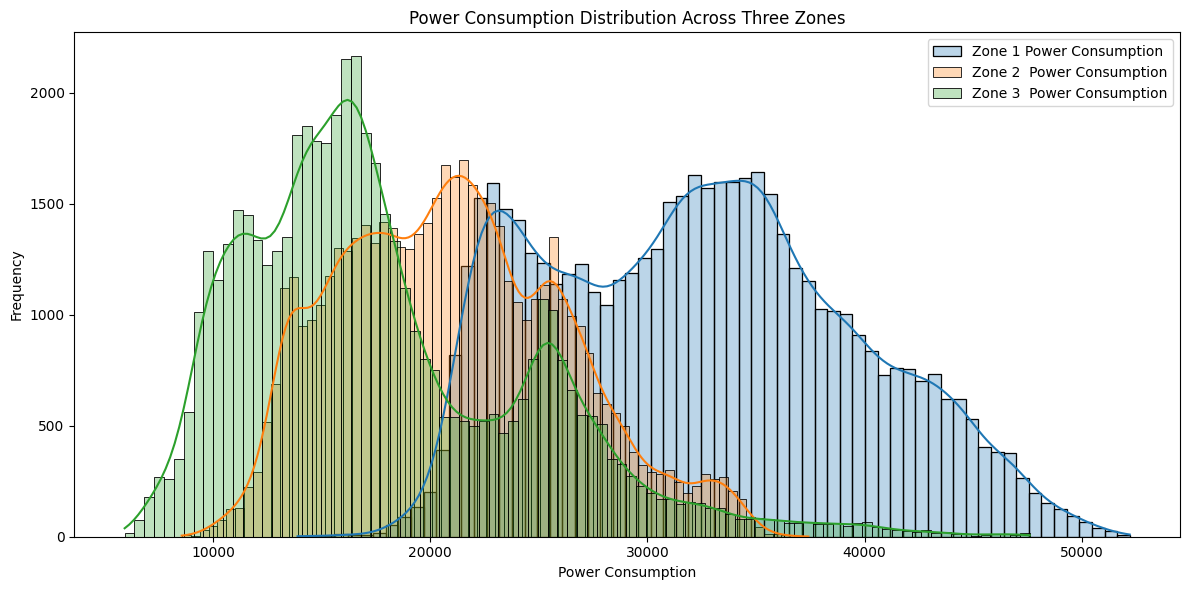

In [2]:
# Convert DateTime column into datetime format
df['DateTime'] = pd.to_datetime(df['DateTime'])

# Sort records by date and time
df = df.sort_values('DateTime').reset_index(drop=True)

# Display date range
print("START DATE:", df['DateTime'].min())
print("END DATE:", df['DateTime'].max())

# Check time interval
print("\nTime Interval:")
print(df['DateTime'].diff().value_counts().head())

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe().round(2))

# Power consumption columns
zones = [
    'Zone 1 Power Consumption',
    'Zone 2  Power Consumption',
    'Zone 3  Power Consumption'
]

# Average consumption by zone
print("\nAVERAGE POWER CONSUMPTION")
display(df[zones].mean().round(2))

# Plot power consumption distributions
plt.figure(figsize=(12, 6))

for zone in zones:
    sns.histplot(df[zone], kde=True, label=zone, alpha=0.3)

plt.title("Power Consumption Distribution Across Three Zones")
plt.xlabel("Power Consumption")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Time-Based Electricity Consumption Analysis

This section examines electricity demand over time, including daily consumption trends and hourly demand patterns across the three zones.

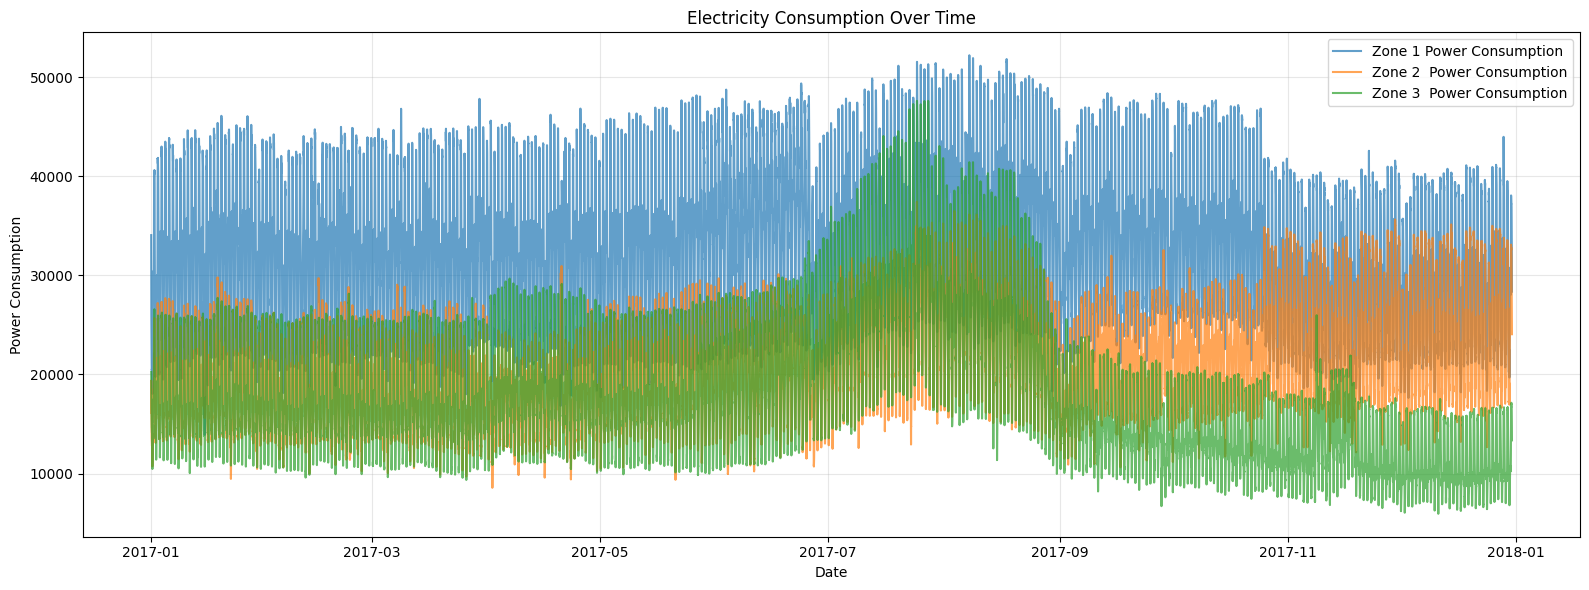

In [3]:
# Plot electricity consumption over time

plt.figure(figsize=(16, 6))

for zone in zones:
    plt.plot(df['DateTime'], df[zone], label=zone, alpha=0.7)

plt.title("Electricity Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Power Consumption")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

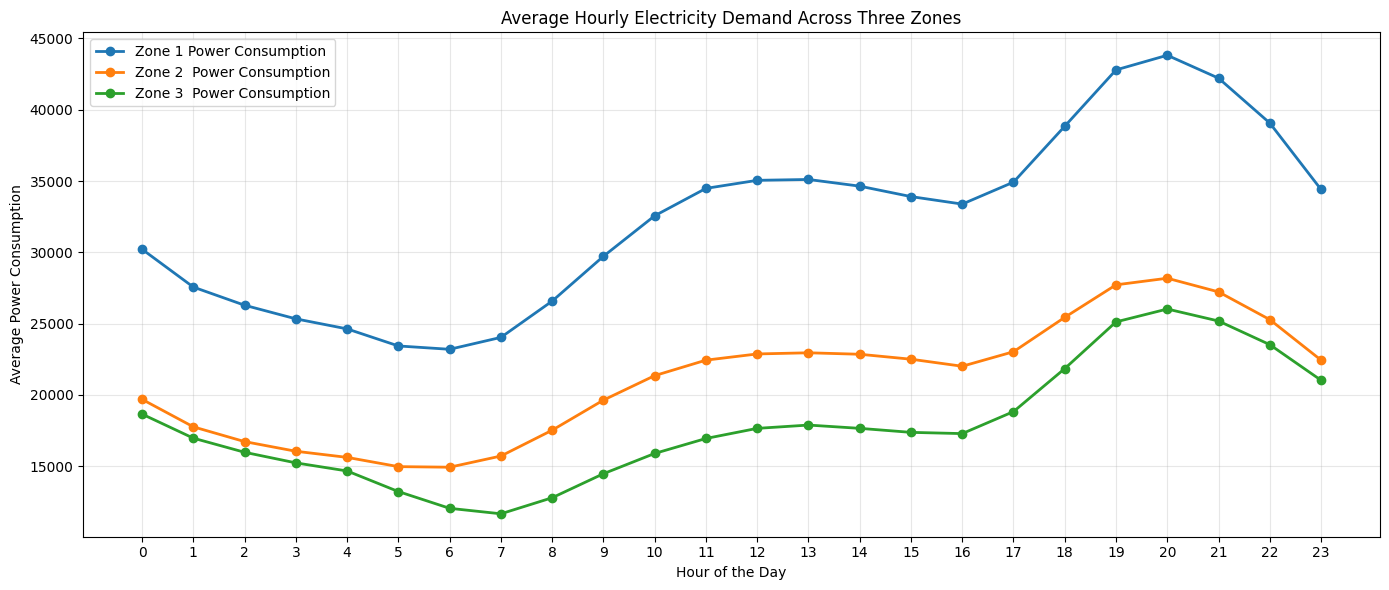

,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
Hour,,,
0,30217.24,19692.07,18657.22
1,27565.53,17765.08,16970.80
2,26292.69,16730.16,15981.10
3,25338.12,16052.59,15238.61
4,24633.58,15624.08,14671.04
5,23437.58,14974.91,13226.38
6,23203.60,14934.70,12051.60
7,24038.35,15719.12,11667.86
8,26583.26,17529.68,12793.79


In [4]:
# Extract time-based features
df['Hour'] = df['DateTime'].dt.hour
df['Day'] = df['DateTime'].dt.day
df['Month'] = df['DateTime'].dt.month
df['DayOfWeek'] = df['DateTime'].dt.dayofweek

# Calculate average hourly consumption
hourly_demand = df.groupby('Hour')[zones].mean()

# Plot hourly demand
hourly_demand.plot(
    figsize=(14, 6),
    marker='o',
    linewidth=2
)

plt.title("Average Hourly Electricity Demand Across Three Zones")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Power Consumption")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(hourly_demand.round(2))

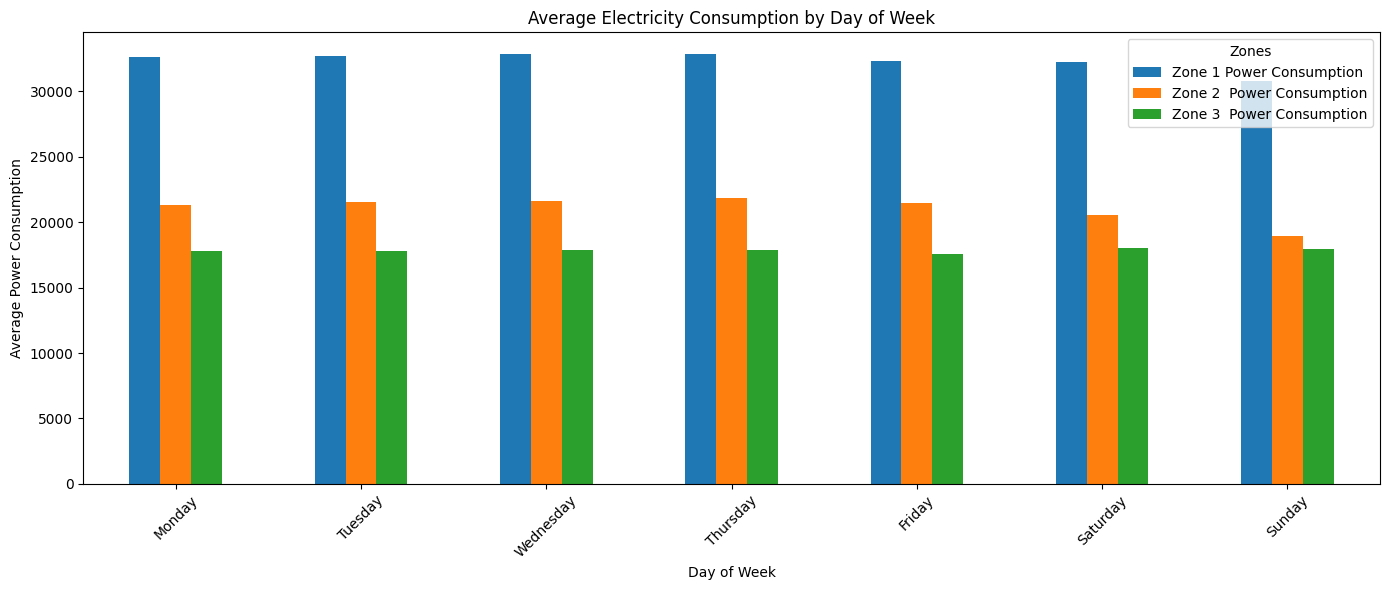

In [5]:
# Calculate average consumption by day of week
daily_demand = df.groupby('DayOfWeek')[zones].mean()

daily_demand.index = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_demand.plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title("Average Electricity Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Power Consumption")
plt.xticks(rotation=45)
plt.legend(title="Zones")
plt.tight_layout()
plt.show()